# DrugTrialPredictor

**Question.** At the moment a clinical drug trial is registered, can we predict whether it will finish
(Q1) and whether it will meet its primary endpoint (Q2)? And do signals from outside the trial's own
design (the sponsor's track record, NIH funding, news and public attention) add predictive power?

**Why it matters.** Roughly one in five drug trials in our cohort is terminated or withdrawn, after
sponsors have spent money and patients have enrolled. An early risk score would help funders, sponsors and
patients decide where to look harder before a trial starts.

**Outline**
1. Data: pull from AACT (ClinicalTrials.gov), build the cohort
2. Features and leakage rules
3. Exploratory data analysis
4. Hypothesis tests
5. Modeling: baselines, ablation, diagnostics
6. Challenges, limitations, next steps

> Draft notes in the *Findings* cells were written from the outputs below. Rewrite them in your own words.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from dtp import config
from dtp.ingest import aact
from dtp import features as F
from dtp import models as M
from dtp import stats as S

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 1. Data

**Source.** [AACT](https://aact.ctti-clinicaltrials.org/) is a free relational copy of ClinicalTrials.gov,
refreshed daily by the Clinical Trials Transformation Initiative. We query its Postgres database with one SQL
statement (`sql/trials.sql`) that builds **one row per trial** by joining and aggregating 13 tables: studies,
designs, sponsors, facilities, countries, conditions, MeSH terms, interventions, eligibility criteria, planned
outcomes, arm types, and posted outcome analyses (for Q2 labels only).

A second query (`sql/sponsor_history.sql`) pulls every interventional trial with its lead sponsor (about
460k rows) so we can compute each sponsor's track record.

**Inclusion criteria**
- Interventional study with at least one drug intervention
- Start date 2005–2019 (later trials are still running, and the ones that have finished are mostly short or stopped)
- Final status: Completed, Terminated, or Withdrawn

The cell below uses the cached pull if it exists; delete `data/interim/*.parquet` to re-pull (≈40 s, needs AACT credentials in `.env`).

In [2]:
raw_path, hist_path = config.INTERIM / "trials_raw.parquet", config.INTERIM / "sponsor_history.parquet"
if raw_path.exists() and hist_path.exists():
    raw, hist = pd.read_parquet(raw_path), pd.read_parquet(hist_path)
else:
    raw = aact.from_postgres(aact.load_sql())
    hist = aact.from_postgres(aact.load_sql("sponsor_history.sql"))
    raw.to_parquet(raw_path, index=False); hist.to_parquet(hist_path, index=False)

print(f"trials: {len(raw):,} rows x {raw.shape[1]} columns | sponsor history: {len(hist):,} rows")
raw["overall_status"].value_counts().to_frame("trials")

trials: 95,726 rows x 39 columns | sponsor history: 461,900 rows


,trials
overall_status,
COMPLETED,78053
TERMINATED,13331
WITHDRAWN,4342


### Cohort: trials that were predictable at registration

ClinicalTrials.gov lets sponsors register a trial late. About 15% of completed trials in the raw pull were
registered **more than a year after they started**, often after they had already finished, compared with
3% of withdrawn trials. A model trained on those rows would learn "registered late ⇒ completed", which is
useless at registration time. We keep only trials registered **no later than 90 days after their start
date**.

In [3]:
full = F.add_design_features(F.add_labels(raw))
lag = full["reg_lag_days"]
print("share registered >365 days after start, by status:")
print((lag > 365).groupby(full["overall_status"]).mean().round(3).to_string())

df = F.build(raw, hist)   # labels + features + sponsor history + cohort filter
cohort = pd.DataFrame({"raw": raw["overall_status"].value_counts(),
                       "cohort": df["overall_status"].value_counts()})
cohort.loc["TOTAL"] = cohort.sum()
cohort["kept"] = cohort["cohort"] / cohort["raw"]
cohort

share registered >365 days after start, by status:
overall_status
COMPLETED     0.148
TERMINATED    0.066
WITHDRAWN     0.033


,raw,cohort,kept
overall_status,,,
COMPLETED,78053,58552,0.750
TERMINATED,13331,11354,0.852
WITHDRAWN,4342,3936,0.906
TOTAL,95726,73842,0.771


## 2. Targets, features and leakage rules

**Targets**
- `completed` (Q1): 1 if Completed, 0 if Terminated or Withdrawn.
- `met_primary` (Q2): among completed trials that posted a primary-outcome p-value, 1 if the smallest such
  p-value is < 0.05. Smaller pool, and it measures whether the drug *worked*, which termination does not.

**Feature groups**
| Group | Examples | Source |
|---|---|---|
| design | phase, allocation, masking, arms, placebo/active comparator, planned primary/secondary outcomes, conditions, 15 disease-area flags (top-level MeSH), eligibility (ages, healthy volunteers, criteria length, biomarker mention) | AACT |
| sponsor_history | sponsor's number of earlier trials, how many had ended, smoothed share stopped | AACT, all trials |
| funding | NIH grants linked to the trial (pending join) | NIH RePORTER |
| hype | news volume/tone, Wikipedia views before start (pending join) | GDELT, Wikimedia |

**Leakage rules.** Every feature must be knowable when the trial is registered:
- No `why_stopped`, posted results, completion dates, or actual enrollment (AACT overwrites the planned
  enrollment with the actual count at the end, so withdrawn trials show 0). These stay in `post_*`/`label_*`
  columns for labels and EDA only.
- Sponsor history counts only trials that **started** (or **ended**) before this trial's start date.
- Site and country counts are excluded: sites are often removed from withdrawn trials (34% of withdrawn trials
  list zero sites vs. 4–7% of others). Section 5 shows how much they would inflate results.
- The registration lag is used for the cohort filter but not as a feature: withdrawn trials keep a *planned*
  start date that is often pushed back before cancellation, so the lag partly records later postponements.

In [4]:
groups = {g: [c for c in cols if c in df.columns] for g, cols in F.FEATURE_GROUPS.items()}
print({g: len(c) for g, c in groups.items()})
print(f"\ncohort: {len(df):,} trials, completion rate {df['completed'].mean():.1%}, "
      f"Q2 rows {df['met_primary'].notna().sum():,}")
miss = df[groups["design"] + groups["sponsor_history"]].isna().mean().sort_values(ascending=False)
miss[miss > 0].head(10).to_frame("missing share")

{'design': 45, 'sponsor_history': 4, 'sites': 3, 'funding': 0, 'hype': 0}

cohort: 73,842 trials, completion rate 79.3%, Q2 rows 9,030


,missing share
elig_max_age_yrs,0.480
n_mesh_terms,0.173
has_dmc,0.142
phase_ord,0.074
number_of_arms,0.043
has_placebo_arm,0.043
has_no_intervention_arm,0.043
has_active_comparator,0.043
elig_min_age_yrs,0.022
n_primary_outcomes,0.004


## 3. Exploratory data analysis

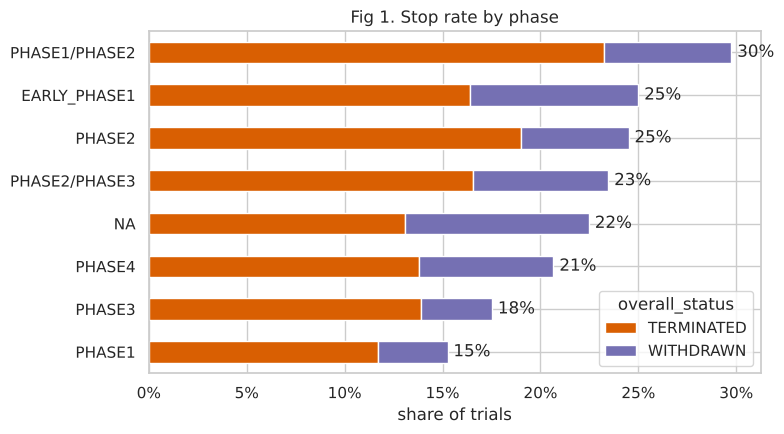

In [5]:
df["stopped"] = 1 - df["completed"]
order = df.groupby("phase")["stopped"].mean().sort_values().index
rates = (pd.crosstab(df["phase"], df["overall_status"], normalize="index")
           .loc[order, ["TERMINATED", "WITHDRAWN"]])
ax = rates.plot.barh(stacked=True, figsize=(8, 4.5), color=["#d95f02", "#7570b3"])
ax.set(xlabel="share of trials", ylabel="", title="Fig 1. Stop rate by phase")
ax.xaxis.set_major_formatter("{x:.0%}")
for i, v in enumerate(rates.sum(axis=1)):
    ax.text(v + 0.003, i, f"{v:.0%}", va="center")
plt.tight_layout(); plt.show()

**Findings (draft).** Phase 1 trials stop least often (≈15%), largely because many are short studies in
healthy volunteers. Phase 2 and combined Phase 1/2 trials stop most often (≈25–30%): this is where a drug
first has to show it works in patients. A phase-only baseline already carries some signal.

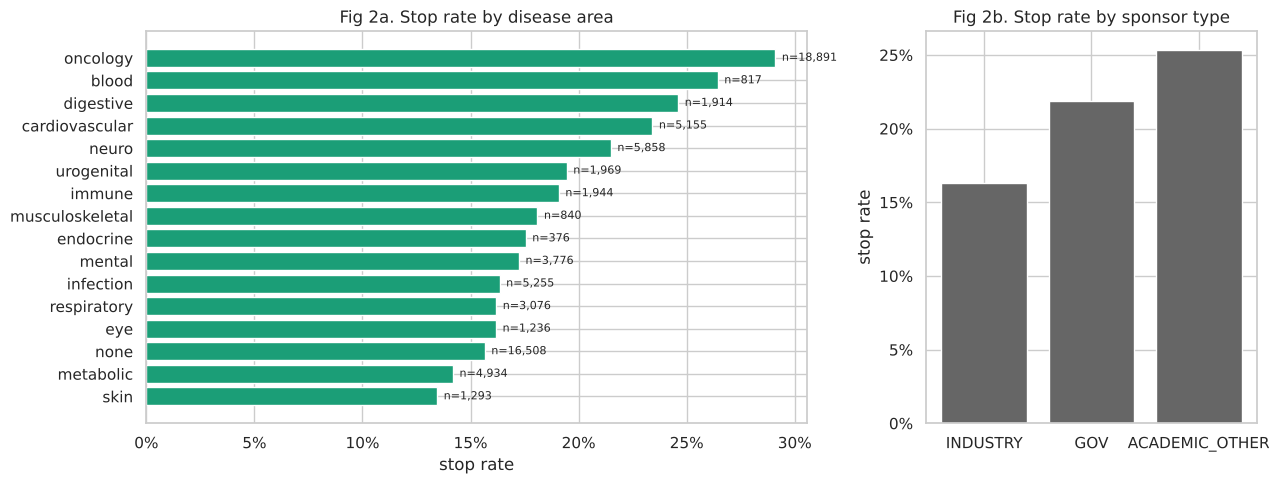

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
area = df.groupby("disease_area")["stopped"].agg(["mean", "size"]).sort_values("mean")
axes[0].barh(area.index, area["mean"], color="#1b9e77")
axes[0].set(title="Fig 2a. Stop rate by disease area", xlabel="stop rate")
axes[0].xaxis.set_major_formatter("{x:.0%}")
for i, (m, n) in enumerate(zip(area["mean"], area["size"])):
    axes[0].text(m + 0.003, i, f"n={n:,}", va="center", fontsize=8)

sp = df.groupby("sponsor_class")["stopped"].mean().sort_values()
axes[1].bar(sp.index, sp.values, color="#666")
axes[1].set(title="Fig 2b. Stop rate by sponsor type", ylabel="stop rate")
axes[1].yaxis.set_major_formatter("{x:.0%}")
plt.tight_layout(); plt.show()

**Findings (draft).** Oncology trials stop most often (≈29%), roughly double skin and metabolic trials.
Industry-sponsored trials stop less often (≈16%) than academic ones (≈25%), the gap tested formally in H1.
Small areas (blood, endocrine) have wide uncertainty; check the n labels before reading much into them.

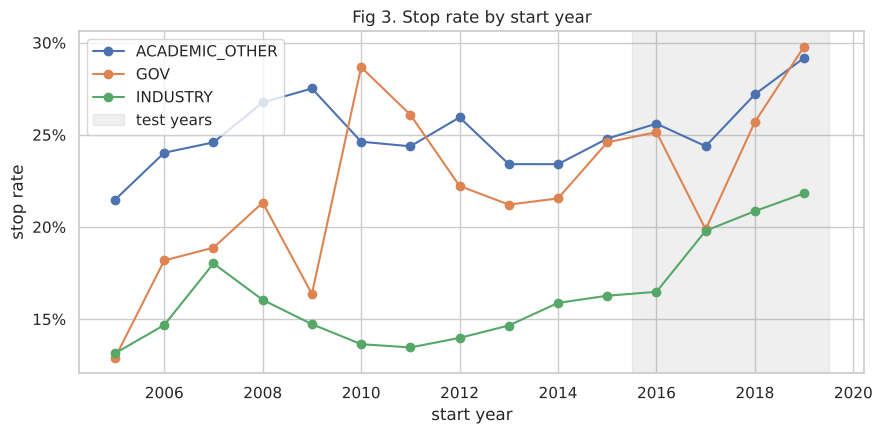

In [7]:
yr = df.groupby(["start_year", "sponsor_class"])["stopped"].mean().unstack()
ax = yr.plot(marker="o", figsize=(9, 4.5))
ax.axvspan(2015.5, 2019.5, color="grey", alpha=0.12, label="test years")
ax.set(title="Fig 3. Stop rate by start year", xlabel="start year", ylabel="stop rate")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter("{x:.0%}"); ax.legend(title="")
plt.tight_layout(); plt.show()

**Findings (draft).** Industry trials stop less often than academic ones in every year. Overall stop rates sit at about 19–21% through 2015, then climb to about 26% by 2019. This is
partly a **censoring effect**: a 2019 trial that is still running is not in the data yet, while one that
stopped early is, so recent years over-represent stopped trials. It matters for modeling because our test
set is 2016–2019: the base rate shifts between train and test. ROC-AUC is unaffected by the base rate, but
calibrated probabilities would be.

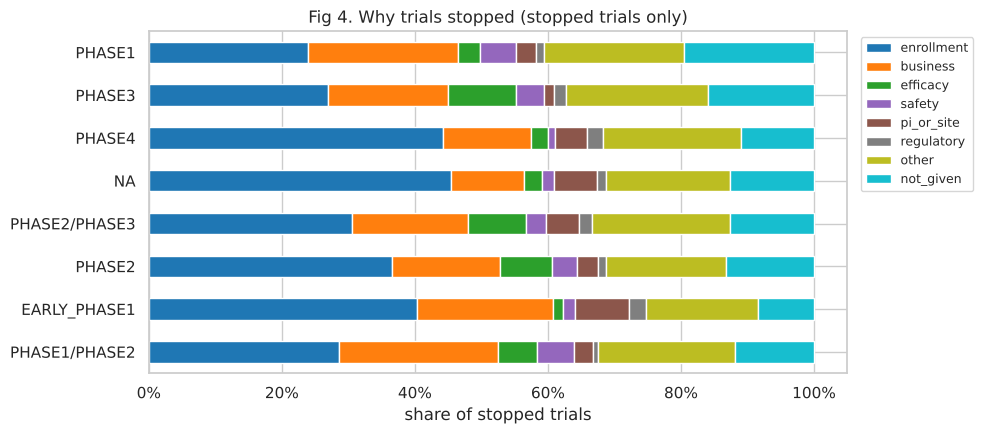

,share
post_stop_reason,
enrollment,0.339
other,0.197
business,0.175
not_given,0.142
efficacy,0.060
safety,0.037
pi_or_site,0.034
regulatory,0.015


In [8]:
stopped = df[df["completed"] == 0]
reasons = (pd.crosstab(stopped["phase"], stopped["post_stop_reason"], normalize="index")
             .loc[order[::-1]])
cols = ["enrollment", "business", "efficacy", "safety", "pi_or_site", "regulatory", "other", "not_given"]
ax = reasons[cols].plot.barh(stacked=True, figsize=(10, 4.5), colormap="tab10")
ax.set(title="Fig 4. Why trials stopped (stopped trials only)", xlabel="share of stopped trials", ylabel="")
ax.xaxis.set_major_formatter("{x:.0%}")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()
stopped["post_stop_reason"].value_counts(normalize=True).to_frame("share")

**Findings (draft).** `why_stopped` is free text; we bucket it with regular expressions (negated phrases
such as "not due to safety concerns" are removed first). **Enrollment problems are the single largest
reason (≈34%)**; business decisions add ≈18%. Only ≈6% stop for efficacy and ≈4% for safety. So
"terminated" mostly means "could not be run," not "the drug failed." That is why Q2 (primary endpoint met)
is modeled separately. Efficacy stops grow with phase (1% in early Phase 1 → 10% in Phase 3).

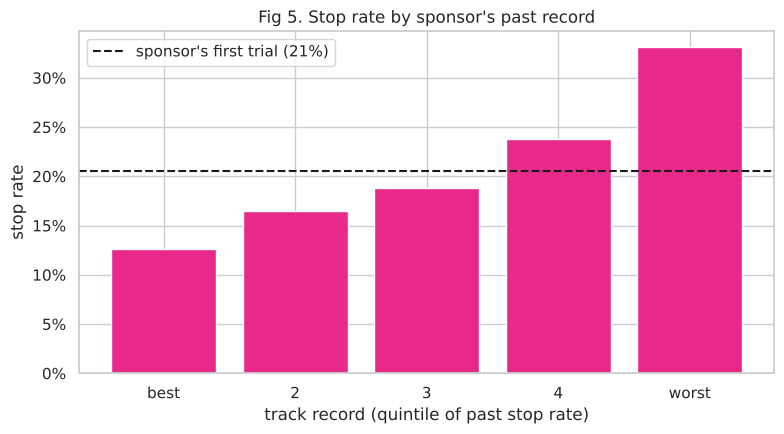

50,419 trials whose sponsor had >=10 earlier trials that ended


In [9]:
x = df[df["sponsor_prior_finished"] >= 10].copy()
x["track record (quintile of past stop rate)"] = pd.qcut(
    x["sponsor_prior_stop_rate"], 5, labels=["best", "2", "3", "4", "worst"])
q = x.groupby("track record (quintile of past stop rate)", observed=True)["stopped"].mean()
first = df.loc[df["sponsor_first_trial"] == 1, "stopped"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(q.index.astype(str), q.values, color="#e7298a")
ax.set_xlabel(q.index.name)
ax.axhline(first, ls="--", color="k", label=f"sponsor's first trial ({first:.0%})")
ax.set(title="Fig 5. Stop rate by sponsor's past record", ylabel="stop rate")
ax.yaxis.set_major_formatter("{x:.0%}"); ax.legend()
plt.tight_layout(); plt.show()
print(f"{len(x):,} trials whose sponsor had >=10 earlier trials that ended")

**Findings (draft).** A sponsor's history is strongly predictive. Among trials whose sponsor had at least
10 earlier trials end, those from the worst-record quintile stop **2.6× as often** as those from the
best (≈33% vs ≈13%). This uses only trials that ended *before* the current one started, so it is
available at registration.

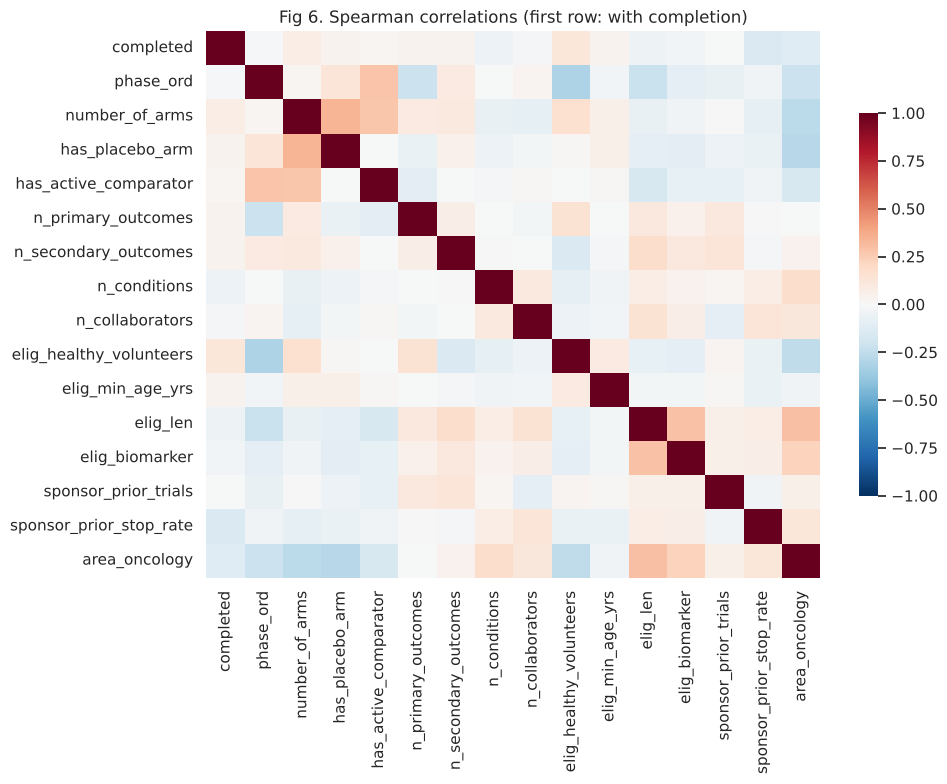

,rho with completed
sponsor_prior_stop_rate,-0.148
area_oncology,-0.122
n_conditions,-0.058
elig_len,-0.050
elig_biomarker,-0.039
n_collaborators,-0.020
phase_ord,-0.013
sponsor_prior_trials,-0.002
has_active_comparator,0.020
has_placebo_arm,0.032


In [10]:
num = ["completed", "phase_ord", "number_of_arms", "has_placebo_arm", "has_active_comparator",
       "n_primary_outcomes", "n_secondary_outcomes", "n_conditions", "n_collaborators",
       "elig_healthy_volunteers", "elig_min_age_yrs", "elig_len", "elig_biomarker",
       "sponsor_prior_trials", "sponsor_prior_stop_rate", "area_oncology"]
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Fig 6. Spearman correlations (first row: with completion)")
plt.tight_layout(); plt.show()
corr["completed"].drop("completed").sort_values().to_frame("rho with completed")

**Findings (draft).** No single feature is strongly correlated with completion (|ρ| < 0.2). The signal is
spread across many weak features, which suggests tree ensembles that combine them will beat any single rule.
The strongest individual associations are the sponsor's past stop rate (negative), healthy-volunteer trials
(positive), and oncology (negative).

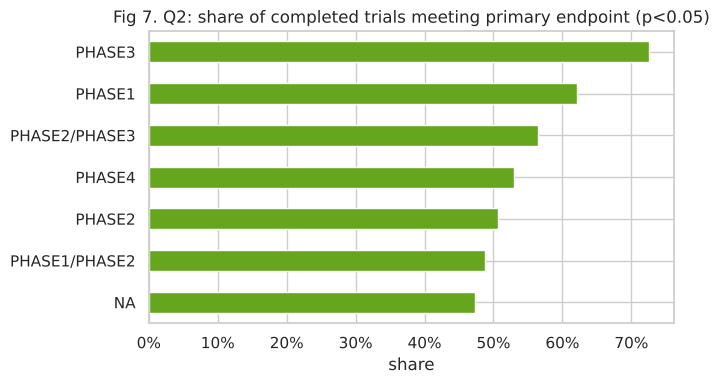

,mean,count
phase,,
NA,0.473,404
PHASE1/PHASE2,0.487,238
PHASE2,0.507,2652
PHASE4,0.530,1297
PHASE2/PHASE3,0.564,234
PHASE1,0.622,259
PHASE3,0.726,3910


In [11]:
qb = df[df["met_primary"].notna()]
t = qb.groupby("phase")["met_primary"].agg(["mean", "count"]).query("count >= 100").sort_values("mean")
ax = t["mean"].plot.barh(color="#66a61e", figsize=(7, 4))
ax.set(title="Fig 7. Q2: share of completed trials meeting primary endpoint (p<0.05)",
       xlabel="share", ylabel="")
ax.xaxis.set_major_formatter("{x:.0%}")
plt.tight_layout(); plt.show()
t

**Findings (draft).** Only about 15% of the cohort's completed trials post a primary-outcome p-value, so Q2
has 9,030 trials. Phase 3 trials hit their endpoint most often (≈73%). They are the ones that already
passed Phase 2, and some p-values are non-inferiority tests. Phase 2 is near a coin flip (≈51%).

## 4. Hypothesis tests

All tests are two-sided **permutation tests**: we shuffle the group labels 10,000 times to simulate the
null distribution of the difference in completion rates, and the p-value is the share of shuffles at least
as extreme as the observed difference.

In [12]:
def show_test(name, res, null=None):
    print(f"{name}: diff = {res['diff']:+.3f}, p = {res['p_value']:.4f} "
          f"(n1={res['n_group1']:,}, n0={res['n_group0']:,})")

# H1: H0 = industry and academic sponsors have the same completion rate
h1 = S.h1_sponsor(df, n_perm=10_000)
show_test("H1 industry vs academic", h1)

# H4: H0 = trials from sponsors with the best and worst past records complete at the same rate
x = df[df["sponsor_prior_finished"] >= 10]
lo, hi = x["sponsor_prior_stop_rate"].quantile([0.25, 0.75])
x = x[(x["sponsor_prior_stop_rate"] <= lo) | (x["sponsor_prior_stop_rate"] >= hi)]
h4 = S.permutation_test(x["completed"], x["sponsor_prior_stop_rate"] <= lo, n_perm=10_000)
show_test("H4 best vs worst track-record quartile", h4)

H1 industry vs academic: diff = +0.090, p = 0.0001 (n1=36,786, n0=33,955)


H4 best vs worst track-record quartile: diff = +0.185, p = 0.0001 (n1=12,618, n0=12,617)


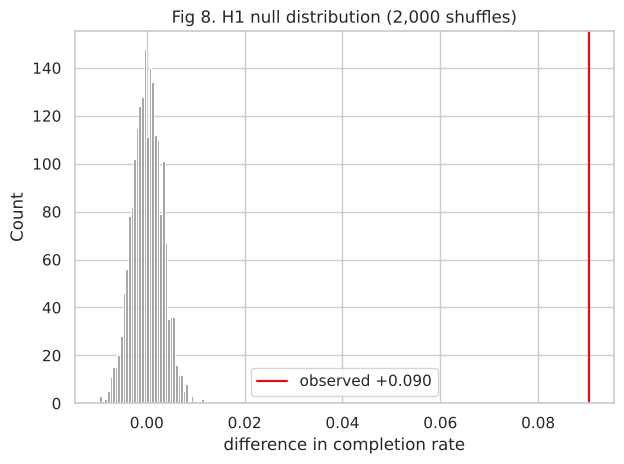

In [13]:
# Visualize H1's null distribution
rng = np.random.default_rng(0)
d = df[df["sponsor_class"].isin(["INDUSTRY", "ACADEMIC_OTHER"])]
y, g = d["completed"].to_numpy(float), (d["sponsor_class"] == "INDUSTRY").to_numpy()
null = [y[p][: g.sum()].mean() - y[p][g.sum():].mean()
        for p in (rng.permutation(len(y)) for _ in range(2000))]
ax = sns.histplot(null, bins=40, color="grey")
ax.axvline(h1["diff"], color="red", label=f"observed {h1['diff']:+.3f}")
ax.set(title="Fig 8. H1 null distribution (2,000 shuffles)", xlabel="difference in completion rate")
ax.legend(); plt.tight_layout(); plt.show()

**Findings (draft).** H1: industry trials complete about 9 percentage points more often than academic trials;
none of the shuffled differences comes close, so we reject H0 (p ≈ 1e-4, the smallest a 10,000-shuffle test
can report). H4: trials from sponsors in the best track-record quartile complete far more often than those in
the worst quartile, again rejecting H0.
Both differences are associations, not causes: industry trials differ in phase mix and disease area too.

**Pending.** H2 (news volume) and H3 (NIH funding) run once the hype and funding joins land
(`dtp.ingest.hype`, `dtp.ingest.nih`).

## 5. Modeling

**Setup**
- **Time split:** train on trials that started 2005–2015, test on 2016–2019. This mimics using the model on
  future trials and avoids leaking era effects across the split.
- **Class imbalance:** about 21% of trials stop. Models use balanced class weights, and we report ROC-AUC
  plus PR-AUC for the *stopped* class (baseline = its prevalence in the test set).
- **Baselines:** majority class, then the training-set stop rate for each (phase, disease area) cell.
- **Models:** regularized logistic regression, random forest, histogram gradient boosting.
- **Ablation:** design only → + sponsor history (→ + funding, + hype once joined).

In [14]:
res = M.run(df, "completed")
res.style.format({c: "{:.3f}" for c in ["roc_auc", "pr_auc", "pr_auc_minority", "f1_minority"]}) \
   .background_gradient(subset=["roc_auc"], cmap="Greens")

,features,model,roc_auc,pr_auc,pr_auc_minority,f1_minority,n_test
0,-,majority,0.500,0.767,0.233,0.000,22078
1,phase+disease,rate_lookup,0.616,0.833,0.305,0.000,22078
2,design,logistic,0.637,0.851,0.321,0.419,22078
3,design,random_forest,0.663,0.865,0.347,0.400,22078
4,design,grad_boost,0.657,0.863,0.342,0.424,22078
5,design+sponsor_history,logistic,0.660,0.859,0.349,0.432,22078
6,design+sponsor_history,random_forest,0.684,0.874,0.367,0.420,22078
7,design+sponsor_history,grad_boost,0.680,0.872,0.365,0.446,22078
8,design+sponsor_history+sites (leaky),logistic,0.663,0.859,0.354,0.433,22078
9,design+sponsor_history+sites (leaky),random_forest,0.726,0.890,0.476,0.452,22078


**Findings (draft).** Each step adds signal. The phase+disease lookup reaches ROC-AUC ≈ 0.62. The
design features reach ≈ 0.66 (random forest and gradient boosting are close). Adding the **sponsor's track
record lifts every model** by about 0.02, to ≈ 0.68. Tree ensembles beat logistic regression, consistent with the weak,
spread-out correlations in Fig 6. Published work on termination prediction reports ≈ 0.73 using
eligibility-text embeddings and without our registration-time cohort filter.

The last block (`+sites (leaky)`) is **not a candidate model**. It shows that adding site counts would
inflate ROC-AUC by about 0.04, almost all of it from withdrawn trials whose sites were removed after the fact.

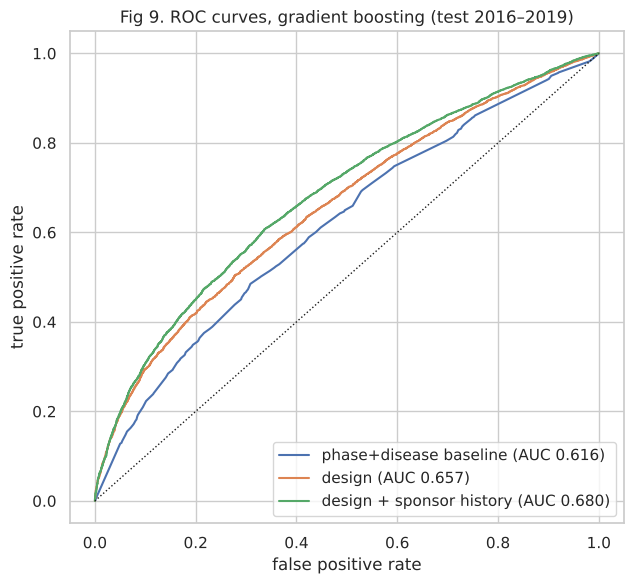

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6))
train, test = M.time_split(df, "completed")
base = M.phase_disease_baseline(train, test, "completed")
curves = {"phase+disease baseline": (test["completed"], base)}
for label, groups in [("design", ["design"]), ("design + sponsor history", ["design", "sponsor_history"])]:
    pipe, cols, t = M.fit(df, "completed", groups)
    curves[label] = (t["completed"], t["pred"])
for label, (y, p) in curves.items():
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{label} (AUC {M.scores(y, p)['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set(title="Fig 9. ROC curves, gradient boosting (test 2016–2019)",
       xlabel="false positive rate", ylabel="true positive rate")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

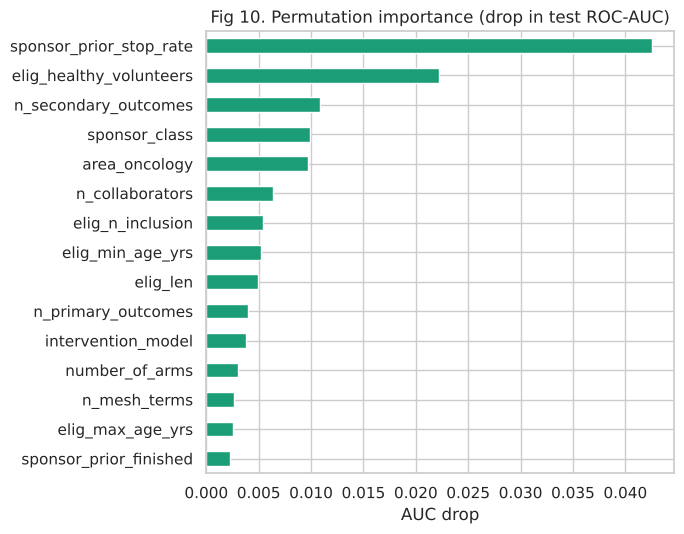

In [16]:
# pipe/cols/t are the design + sponsor history gradient-boosting model from the cell above
imp = M.importance(pipe, t, cols, "completed")
ax = imp.head(15)[::-1].plot.barh(figsize=(7, 5.5), color="#1b9e77")
ax.set(title="Fig 10. Permutation importance (drop in test ROC-AUC)", xlabel="AUC drop")
plt.tight_layout(); plt.show()

**Findings (draft).** The sponsor's past stop rate is the most important feature by a wide margin, followed
by healthy-volunteer status, sponsor type, the number of planned secondary outcomes, and number of
collaborators. Disease area (especially oncology) and eligibility-criteria length also matter. No single
feature dominates, which matches the EDA.

In [17]:
by_phase = M.auc_by_group(t, "completed", "phase")
by_sponsor = M.auc_by_group(t, "completed", "sponsor_class")
display(by_phase, by_sponsor)

,phase,n,rate,roc_auc
4,PHASE2,5967,0.720,0.634
2,PHASE1,5297,0.817,0.743
6,PHASE3,3503,0.795,0.640
7,PHASE4,3219,0.756,0.663
1,NA,1543,0.846,0.690
3,PHASE1/PHASE2,1411,0.648,0.605
0,EARLY_PHASE1,591,0.739,0.648
5,PHASE2/PHASE3,547,0.771,0.643


,sponsor_class,n,rate,roc_auc
0,ACADEMIC_OTHER,11321,0.735,0.655
2,INDUSTRY,10115,0.803,0.702
1,GOV,642,0.749,0.619


**Findings (draft).** The model ranks risk best for Phase 1 trials (AUC ≈ 0.74) and worst for Phase 1/2,
Phase 2 and Phase 3 (≈ 0.61–0.64), the phases where whether the drug works starts to matter. Signals about
trial design can't capture that. It does better on industry trials (≈ 0.70) than academic ones (≈ 0.66).

### Q2: did the trial meet its primary endpoint?

In [18]:
res_b = M.run(df, "met_primary", ablations={k: M.ABLATIONS[k] for k in ["design", "design+sponsor_history"]})
res_b.style.format({c: "{:.3f}" for c in ["roc_auc", "pr_auc", "pr_auc_minority", "f1_minority"]})

,features,model,roc_auc,pr_auc,pr_auc_minority,f1_minority,n_test
0,-,majority,0.500,0.616,0.384,0.000,2464
1,phase+disease,rate_lookup,0.637,0.733,0.490,0.441,2464
2,design,logistic,0.710,0.784,0.585,0.591,2464
3,design,random_forest,0.729,0.805,0.618,0.598,2464
4,design,grad_boost,0.707,0.787,0.583,0.573,2464
5,design+sponsor_history,logistic,0.709,0.782,0.582,0.593,2464
6,design+sponsor_history,random_forest,0.727,0.802,0.617,0.602,2464
7,design+sponsor_history,grad_boost,0.706,0.786,0.577,0.581,2464


**Findings (draft).** Design features predict whether a completed trial hit its endpoint about as well as
they predict completion (ROC-AUC ≈ 0.71–0.73, vs ≈ 0.64 for the phase+disease lookup). But the **sponsor's
track record adds nothing here**: a sponsor's history tells us whether it can *run* a trial to the end, not
whether its drug *works*. The test set is small (≈2.5k trials), so differences under ~0.02 are noise.

## 6. Challenges, limitations and next steps

**Challenges**
- *Leakage hides in plain sight.* Three features looked strong and turned out to encode the outcome: late
  registration, site counts, and the registration lag of withdrawn trials (postponed planned start dates).
  Each needed a cohort rule or exclusion.
- *Termination ≠ failure.* Most stopped trials stopped over enrollment or business reasons (Fig 4), which
  caps how well design features can predict efficacy.
- *Censoring.* Recent cohorts over-represent stopped trials (Fig 3).
- *Query performance.* AACT's planner picked nested loops for the 13-table join (minutes per year of data);
  disabling them brought the full pull to ≈30 s.

**Limitations**
- Anticipated enrollment, likely a strong feature, is not available: AACT keeps only the final count.
  Recovering it requires the ClinicalTrials.gov record history for each trial.
- Planned outcomes and eligibility text can be edited after registration; we use the latest version.
- The Q2 label (smallest primary p < 0.05) ignores non-inferiority designs and multiple testing.

**Next steps**
1. Join NIH funding (H3) and news/Wikipedia attention (H2), then extend the ablation.
2. Recover anticipated enrollment from record history for at least a sample.
3. Tune gradient boosting; calibrate probabilities for the shifted test-year base rate.
4. Text features from eligibility criteria and trial descriptions (embeddings), the stretch "AI science" read.